In [8]:
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt


Matplotlib is building the font cache; this may take a moment.


In [9]:
plt.style.use('ggplot')

client = clickhouse_connect.get_client(
    host='localhost',
    port=8123, 
    username='default',
    password='my_secret_password'
    )    

querry = "SELECT * FROM ads_analytics_hourly" 
df = client.query_df(querry)
print(f"успешно подключились к клихаус и получили {len(df)} строк данных")
df.head(10)

успешно подключились к клихаус и получили 18 строк данных


,hour,device_type,placement,total_impressions,total_clicks,avg_page_load_ms,avg_bid_price,ctr_percentage
0,2026-10-20 00:00:00,desktop,catalog,111,1,2502,79.000000,0.900901
1,2026-10-20 00:00:00,desktop,recommendations,130,3,2630,70.449997,2.307692
2,2026-10-20 00:00:00,desktop,search,124,2,2501,72.849998,1.612903
3,2026-10-20 00:00:00,mobile,catalog,115,5,2439,81.389999,4.347826
4,2026-10-20 00:00:00,mobile,recommendations,119,3,2593,74.510002,2.521008
5,2026-10-20 00:00:00,mobile,search,120,8,2476,69.870003,6.666667
6,2026-10-20 00:00:00,tablet,catalog,136,4,2533,76.239998,2.941176
7,2026-10-20 00:00:00,tablet,recommendations,124,2,2550,76.099998,1.612903
8,2026-10-20 00:00:00,tablet,search,117,4,2381,75.330002,3.418803
9,2026-10-20 01:00:00,desktop,catalog,433,11,2466,78.589996,2.540416


In [11]:
def counts_device_type_hourly(df:pd.DataFrame, device_name:str):
    df_device = df[df['device_type'] == device_name]
    counts = df_device.groupby('hour')['device_type'].count()
    return counts


In [12]:
tablet_count = counts_device_type_hourly(df, 'tablet')

print(f"Количество записей для планшетов: {len(tablet_count)}")
print(tablet_count)

Количество записей для планшетов: 2
hour
2026-10-20 00:00:00    3
2026-10-20 01:00:00    3
Name: device_type, dtype: int64


In [15]:
print(tablet_count.sum())

6


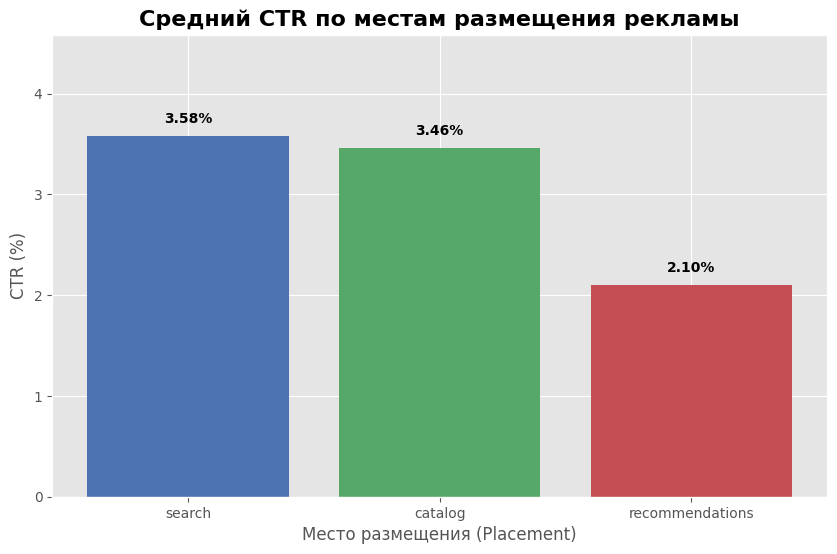

In [16]:
plt.figure(figsize=(10, 6))


placement_ctr = df.groupby('placement')['ctr_percentage'].mean().sort_values(ascending=False)


bars = plt.bar(placement_ctr.index, placement_ctr.values, color=['#4C72B0', '#55A868', '#C44E52'])

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.1, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.title('Средний CTR по местам размещения рекламы', fontsize=16, fontweight='bold')
plt.xlabel('Место размещения (Placement)', fontsize=12)
plt.ylabel('CTR (%)', fontsize=12)
plt.ylim(0, max(placement_ctr.values) + 1)


plt.savefig('ctr_by_placement.png', bbox_inches='tight', dpi=300)

plt.show()

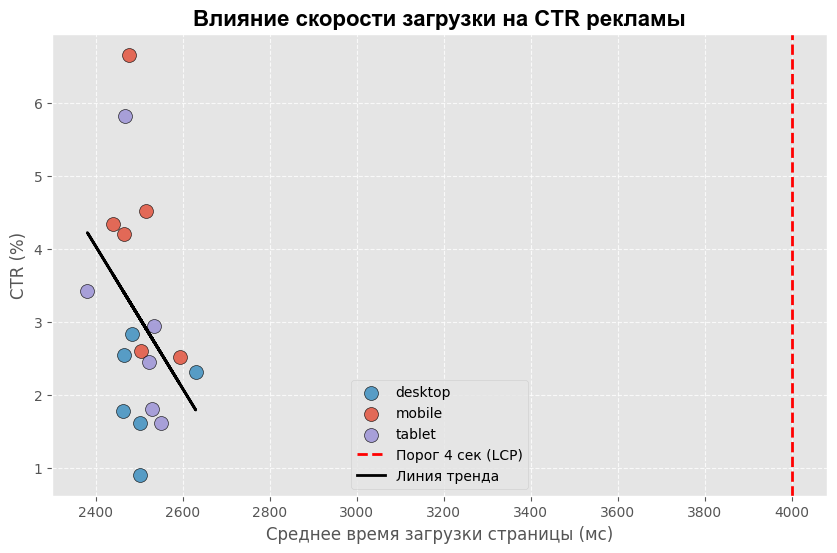

In [ ]:
import numpy as np
plt.figure(figsize=(10, 6))


colors = {'mobile': '#E24A33', 'desktop': '#348ABD', 'tablet': '#988ED5'}


for device in df['device_type'].unique():
    subset = df[df['device_type'] == device]
    plt.scatter(
        subset['avg_page_load_ms'], 
        subset['ctr_percentage'], 
        label=device, 
        alpha=0.8, 
        color=colors.get(device, 'gray'),
        s=100, # Размер точек
        edgecolors='black' # Черная обводка для красоты
    )


plt.axvline(x=4000, color='red', linestyle='--', linewidth=2, label='Порог 4 сек (LCP)')

plt.title('Влияние скорости загрузки на CTR рекламы', fontsize=16, fontweight='bold', fontname='Arial')
plt.xlabel('Среднее время загрузки страницы (мс)', fontsize=12)
plt.ylabel('CTR (%)', fontsize=12)
plt.legend(title='Тип устройства', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.8)





x = df['avg_page_load_ms']
y = df['ctr_percentage']
coefficients = np.polyfit(x, y, 1) 
polynomial = np.poly1d(coefficients)
plt.plot(x, polynomial(x), color='black', linewidth=2, linestyle='-', label='Линия тренда')

plt.legend()
plt.savefig('speed_vs_ctr.png', bbox_inches='tight', dpi=300)
plt.show()

### Выводы по результатам исследования

 1.##Эффективность мест размещения:** 
   На основе первого графика видно, что наивысший CTR наблюдается в блоке **search** (поиск). Это означает, что реклама в поиске наиболее релевантна запросам пользователей. Рекомендации (recommendations) показывают самый низкий CTR, что может требовать доработки алгоритмов ранжирования.

 2.**Влияние скорости загрузки:**
   На точечном графике (speed_vs_ctr) заметно, что при времени загрузки страницы превышающем **4000 мс** (красная линия), разброс CTR становится выше, а средние значения падают. Это подтверждает гипотезу: медленная загрузка негативно сказывается на кликабельности рекламы.

 3.**Разница по устройствам:**
   Мобильные устройства (mobile) демонстрируют более высокое время загрузки по сравнению с десктопом, что является точкой роста для оптимизации фронтенда.
